In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt

In [3]:
import sys
print(sys.executable)

D:\Credit-card- fraud- detection\venv\Scripts\python.exe


In [4]:
import seaborn as sns

In [5]:
df=pd.read_csv("data/creditcard.csv")

In [6]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [7]:
df.shape

(284807, 31)

In [8]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [9]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21 

In [10]:
print("\nMissing values:")
print(df.isnull().sum().sum())


Missing values:
0


In [11]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 1081


In [12]:
print(df["Class"].value_counts())

Class
0    284315
1       492
Name: count, dtype: int64


In [13]:
print("\nPercentage of each class:")
print((df["Class"].value_counts(normalize=True) * 100).round(4))


Percentage of each class:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


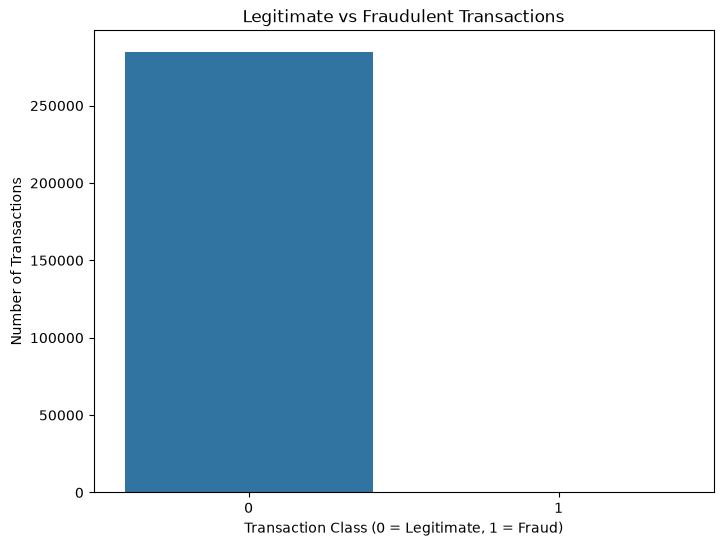

In [14]:
plt.figure(figsize=(8, 6))

sns.countplot(data=df, x="Class")

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.show()

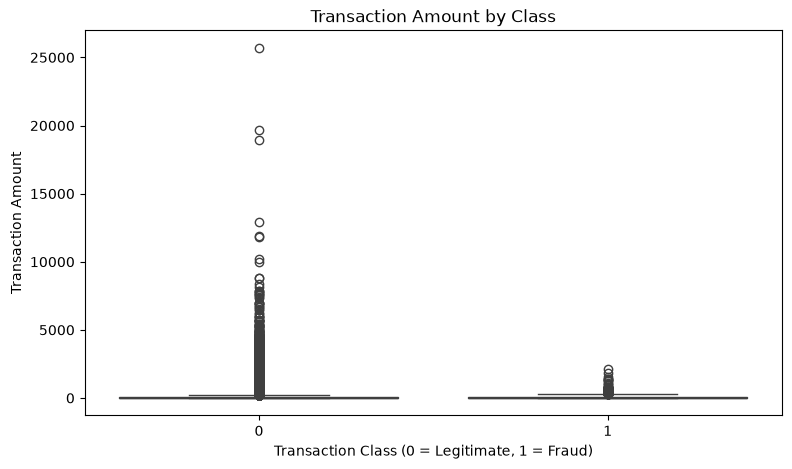

In [15]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="Class", y="Amount")

plt.title("Transaction Amount by Class")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")

plt.show()

In [16]:
summary = {
    "Total Transactions": len(df),
    "Total Features": df.shape[1] - 1,
    "Legitimate Transactions": int((df["Class"] == 0).sum()),
    "Fraudulent Transactions": int((df["Class"] == 1).sum()),
    "Missing Values": int(df.isnull().sum().sum()),
    "Duplicate Rows": int(df.duplicated().sum())
}

for key, value in summary.items():
    print(f"{key}: {value}")

Total Transactions: 284807
Total Features: 30
Legitimate Transactions: 284315
Fraudulent Transactions: 492
Missing Values: 0
Duplicate Rows: 1081


In [17]:
print(df["Class"].value_counts())
print("\nFraud percentage:")
print(round(df["Class"].mean() * 100, 4), "%")

Class
0    284315
1       492
Name: count, dtype: int64

Fraud percentage:
0.1727 %


In [18]:
duplicate_count = df.duplicated().sum()
print("Total rows:", len(df))
print("Duplicate rows:", duplicate_count)

Total rows: 284807
Duplicate rows: 1081


In [19]:
duplicates = df[df.duplicated(keep=False)]
duplicates.head(10)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
220,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0
221,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0


In [20]:
print("Rows before cleaning:", len(df))
print("Duplicate rows found:", df.duplicated().sum())

Rows before cleaning: 284807
Duplicate rows found: 1081


In [21]:
df_clean = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Duplicates remaining:", df_clean.duplicated().sum())
print("Rows after cleaning:", len(df_clean))
print("Duplicates remaining:", df_clean.duplicated().sum())

Original dataset shape: (284807, 31)
Cleaned dataset shape: (283726, 31)
Duplicates remaining: 0
Rows after cleaning: 283726
Duplicates remaining: 0


In [22]:
X = df_clean.drop(columns=["Class"])
y = df_clean["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (283726, 30)
Target shape: (283726,)


Feature correlation with Fraud (Class):
Class     1.000000
V11       0.149067
V4        0.129326
V2        0.084624
V19       0.033631
V8        0.033068
V21       0.026357
V27       0.021892
V20       0.021486
V28       0.009682
Amount    0.005777
V22       0.004887
V26       0.004265
V25       0.003202
V15      -0.003300
V13      -0.003897
V23      -0.006333
V24      -0.007210
Time     -0.012359
V6       -0.043915
V5       -0.087812
V9       -0.094021
V1       -0.094486
V18      -0.105340
V7       -0.172347
V3       -0.182322
V16      -0.187186
V10      -0.206971
V12      -0.250711
V14      -0.293375
V17      -0.313498
Name: Class, dtype: float64


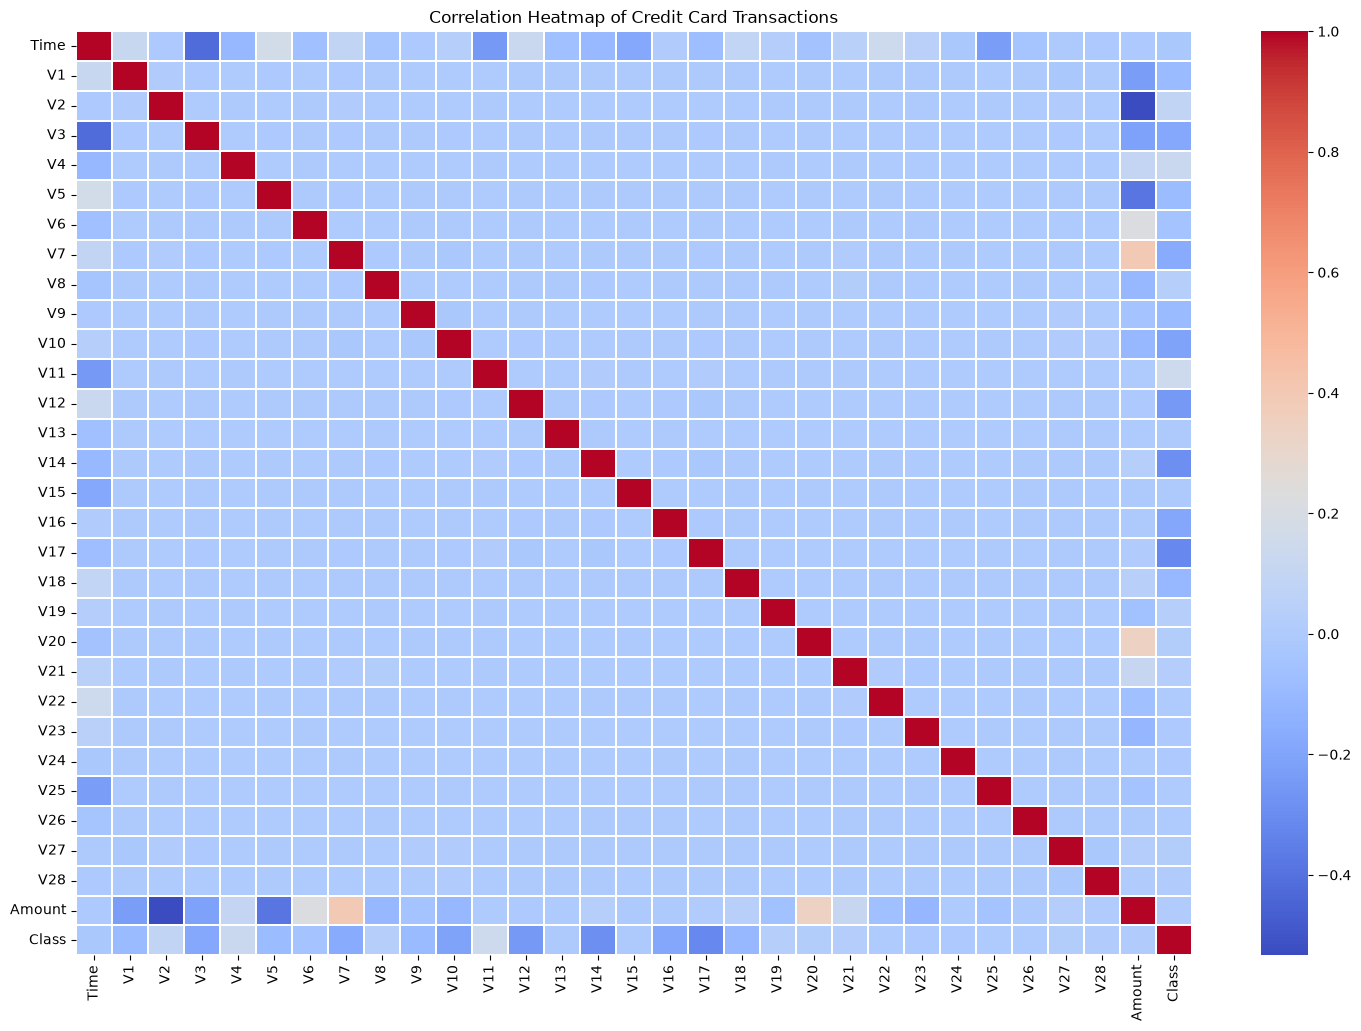

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation matrix
correlation_matrix = df_clean.corr()

# Display correlation with target variable
fraud_correlation = correlation_matrix["Class"].sort_values(
    ascending=False
)

print("Feature correlation with Fraud (Class):")
print(fraud_correlation)

# Plot correlation heatmap
plt.figure(figsize=(18, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    annot=False,
    linewidths=0.2
)

plt.title("Correlation Heatmap of Credit Card Transactions")
plt.show()

In [23]:
from sklearn.model_selection import train_test_split

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [25]:
from pathlib import Path
import pandas as pd

# Create a test dataset with actual labels
test_data = X_test.copy()
test_data["Class"] = y_test

# Save the test dataset
output_path = Path("data/test_transactions.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

test_data.to_csv(output_path, index=False)

print("Test dataset saved to:", output_path.resolve())
print("Test transactions:", len(test_data))
print("\nActual class distribution:")
print(test_data["Class"].value_counts())

Test dataset saved to: D:\Credit-card- fraud- detection\data\test_transactions.csv
Test transactions: 56746

Actual class distribution:
Class
0    56651
1       95
Name: count, dtype: int64


In [26]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (226980, 30)
Testing features: (56746, 30)

Training target distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Testing target distribution:
Class
0    56651
1       95
Name: count, dtype: int64


In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [28]:
scaler = StandardScaler()

In [29]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (226980, 30)
Scaled testing data shape: (56746, 30)


In [30]:
from sklearn.linear_model import LogisticRegression

In [31]:
lr=LogisticRegression(max_iter=1000,class_weight="balanced",random_state=42)

In [32]:
lr.fit(X_train_scaled,y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [33]:
from sklearn.metrics import confusion_matrix, accuracy_score, average_precision_score,classification_report

In [34]:
y_pred = lr.predict(X_test_scaled)

In [35]:
y_scores = lr.predict_proba(X_test_scaled)[:, 1]

In [36]:
print(y_scores)

[0.02332011 0.02102659 0.01241493 ... 0.04488547 0.04933063 0.02731424]


In [37]:
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746



In [38]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Confusion Matrix:
[[55277  1374]
 [   12    83]]


In [39]:
print(
    "Average Precision:",
    round(average_precision_score(y_test, y_scores), 4)
)

Average Precision: 0.6743


In [40]:
print("Accuracy Score:")
print(accuracy_score(y_test,y_pred))

Accuracy Score:
0.9755753709512565


In [41]:
import pickle
from pathlib import Path

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

with open(model_dir / "fraud_detection_model.pkl", "wb") as f:
    pickle.dump(lr, f)

with open(model_dir / "scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


In [42]:
from sklearn.ensemble import RandomForestClassifier

In [47]:
rf=RandomForestClassifier(n_estimators=1000,class_weight='balanced',random_state=42,n_jobs=-1)

In [48]:
rf.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",1000
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_f

In [49]:
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score,average_precision_score,ConfusionMatrixDisplay

In [50]:
y_pred_rf=rf.predict(X_test)

In [51]:
y_pred_rf_score = rf.predict_proba(X_test)[:, 1]

In [52]:
print("Classification Report:")
print(classification_report(y_test,y_pred_rf,zero_division=0))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.96      0.73      0.83        95

    accuracy                           1.00     56746
   macro avg       0.98      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746



In [53]:
print("Confusion Matrix:")
print(confusion_matrix(y_test,y_pred_rf))

Confusion Matrix:
[[56648     3]
 [   26    69]]


Confusion Matrix:
[[56648     3]
 [   26    69]]


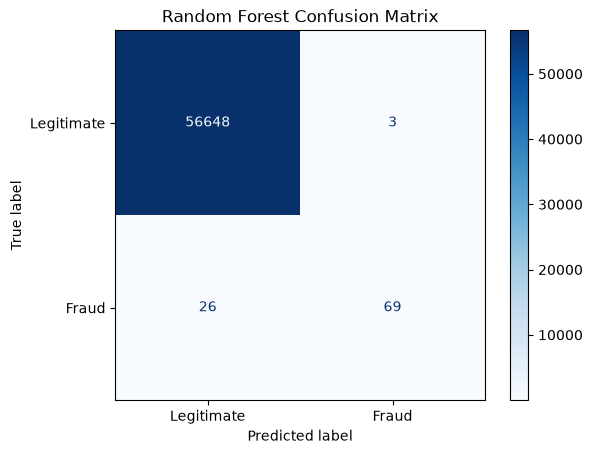

In [54]:
cm = confusion_matrix(y_test, y_pred_rf)
print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"]
).plot(cmap="Blues")

plt.title("Random Forest Confusion Matrix")
plt.show()

In [55]:
print("Accuracy Score:")
print(accuracy_score(y_test,y_pred_rf))

Accuracy Score:
0.9994889507630493


In [56]:
print("Average Precision Score:")
print(average_precision_score(y_test,y_pred_rf_score))

Average Precision Score:
0.8193627629129785


   Feature  Importance
14     V14    0.171423
10     V10    0.130330
12     V12    0.112363
4       V4    0.093967
17     V17    0.093687
11     V11    0.071358
3       V3    0.059135
16     V16    0.038194
7       V7    0.025430
2       V2    0.023686


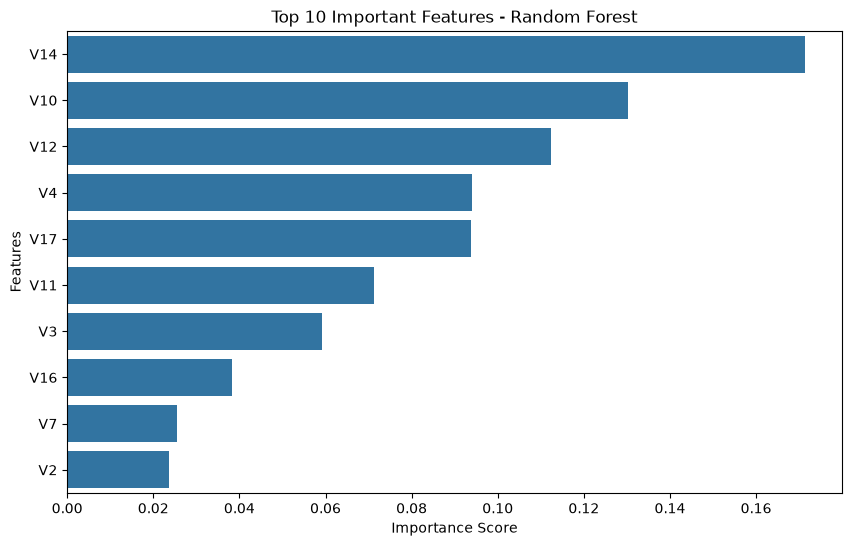

In [64]:


# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(10))

# Plot top 10 important features
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

In [57]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ],
    "Average Precision": [
        average_precision_score(y_test, y_scores),
        average_precision_score(y_test, y_pred_rf_score)
    ]
})

comparison.round(4)

,Model,Precision,Recall,F1 Score,Average Precision
0,Logistic Regression,0.0570,0.8737,0.1070,0.6743
1,Random Forest,0.9583,0.7263,0.8263,0.8194


In [58]:
import pickle
from pathlib import Path

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

with open(model_dir / "random_forest_model.pkl", "wb") as f:
    pickle.dump(rf, f)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [59]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

# Get fraud probabilities from the test set
y_pred_rf_score = rf.predict_proba(X_test)[:, 1]

results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
    predictions = (y_pred_rf_score >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn
    })

threshold_results = pd.DataFrame(results)
threshold_results.round(4)

,Threshold,Precision,Recall,F1 Score,False Positives,False Negatives
0,0.1,0.7429,0.8211,0.7800,27,17
1,0.2,0.8444,0.8000,0.8216,14,19
2,0.3,0.9250,0.7789,0.8457,6,21
3,0.4,0.9211,0.7368,0.8187,6,25
4,0.5,0.9583,0.7263,0.8263,3,26


In [60]:
import pickle
from pathlib import Path

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

with open(model_dir / "best_fraud_detection_model.pkl", "wb") as f:
    pickle.dump(rf, f)

with open(model_dir / "fraud_threshold.pkl", "wb") as f:
    pickle.dump(0.3, f)

print("Random Forest model saved!")
print("Selected fraud threshold: 0.3")

Random Forest model saved!
Selected fraud threshold: 0.3


In [62]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)
import pandas as pd

# Logistic Regression predictions
lr_pred = lr.predict(X_test_scaled)
lr_scores = lr.predict_proba(X_test_scaled)[:, 1]

# Random Forest predictions at threshold 0.30
rf_scores = rf.predict_proba(X_test)[:, 1]
rf_pred = (rf_scores >= 0.30).astype(int)

# Create comparison
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, lr_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, lr_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1 Score": [
        f1_score(y_test, lr_pred),
        f1_score(y_test, rf_pred)
    ],
    "Average Precision": [
        average_precision_score(y_test, lr_scores),
        average_precision_score(y_test, rf_scores)
    ]
})

print(comparison.round(4))


                 Model  Accuracy  Precision  Recall  F1 Score  \
0  Logistic Regression    0.9756      0.057  0.8737    0.1070   
1        Random Forest    0.9995      0.925  0.7789    0.8457   

   Average Precision  
0             0.6743  
1             0.8194  
